In [5]:

import pandas as pd

df = pd.read_csv('/content/train.csv')

df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [8]:
df.shape


(1460, 81)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [10]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [11]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


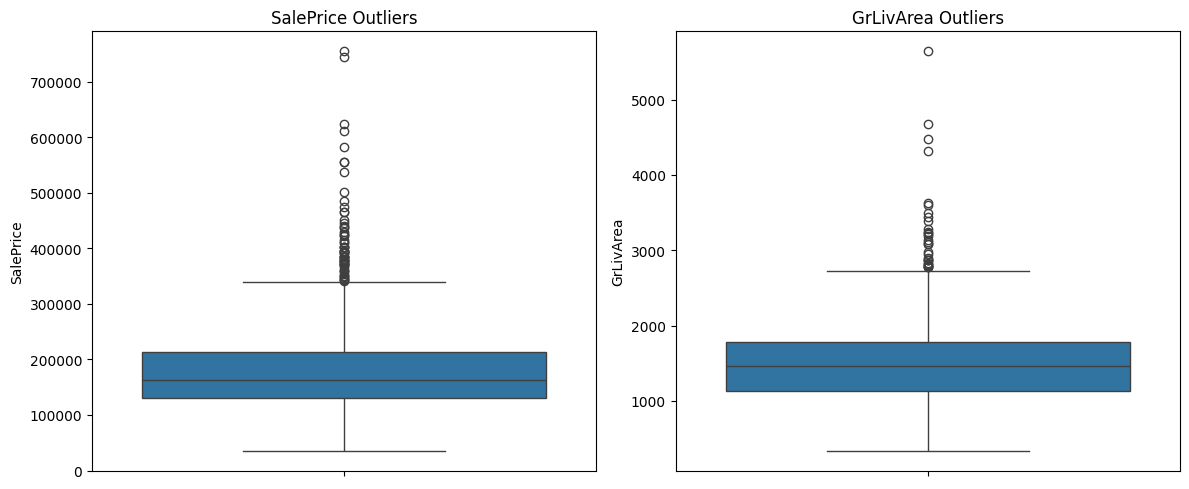

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['SalePrice'])
plt.title('SalePrice Outliers')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['GrLivArea'])
plt.title('GrLivArea Outliers')

plt.tight_layout()
plt.show()


In [13]:

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(col, ":", df[col].nunique())


MSZoning : 5
Street : 2
Alley : 2
LotShape : 4
LandContour : 4
Utilities : 2
LotConfig : 5
LandSlope : 3
Neighborhood : 25
Condition1 : 9
Condition2 : 8
BldgType : 5
HouseStyle : 8
RoofStyle : 6
RoofMatl : 8
Exterior1st : 15
Exterior2nd : 16
MasVnrType : 3
ExterQual : 4
ExterCond : 5
Foundation : 6
BsmtQual : 4
BsmtCond : 4
BsmtExposure : 4
BsmtFinType1 : 6
BsmtFinType2 : 6
Heating : 6
HeatingQC : 5
CentralAir : 2
Electrical : 5
KitchenQual : 4
Functional : 7
FireplaceQu : 5
GarageType : 6
GarageFinish : 3
GarageQual : 5
GarageCond : 5
PavedDrive : 3
PoolQC : 3
Fence : 4
MiscFeature : 4
SaleType : 9
SaleCondition : 6


In [14]:

cols_none = [
    'PoolQC',
    'MiscFeature',
    'Alley',
    'Fence',
    'FireplaceQu'
]

df[cols_none] = df[cols_none].fillna('None')


In [15]:

df[cols_none].isnull().sum()


,0
PoolQC,0
MiscFeature,0
Alley,0
Fence,0
FireplaceQu,0


In [16]:

garage_cols = [
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond'
]

df[garage_cols] = df[garage_cols].fillna('None')

df[garage_cols].isnull().sum()


,0
GarageType,0
GarageFinish,0
GarageQual,0
GarageCond,0


In [17]:

basement_cols = [
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2'
]

df[basement_cols] = df[basement_cols].fillna('None')

df[basement_cols].isnull().sum()



,0
BsmtQual,0
BsmtCond,0
BsmtExposure,0
BsmtFinType1,0
BsmtFinType2,0


In [19]:

df['MasVnrType'] = df['MasVnrType'].fillna('None')

df['MasVnrArea'] = df['MasVnrArea'].fillna(0)

print(df[['MasVnrType', 'MasVnrArea']].isnull().sum())



MasVnrType    0
MasVnrArea    0
dtype: int64


In [20]:

median_value = df['LotFrontage'].median()

df['LotFrontage'] = df['LotFrontage'].fillna(median_value)

print(df['LotFrontage'].isnull().sum())


0


In [21]:

df['GarageYrBlt'] = df['GarageYrBlt'].fillna(
    df['GarageYrBlt'].median()
)

df['Electrical'] = df['Electrical'].fillna(
    df['Electrical'].mode()[0]
)

print(df[['GarageYrBlt', 'Electrical']].isnull().sum())




GarageYrBlt    0
Electrical     0
dtype: int64


In [22]:

df.loc[df['GarageType'] == 'None', 'GarageYrBlt'] = 0

In [23]:

print("Total Missing Values:", df.isnull().sum().sum())

print(df.isnull().sum()[df.isnull().sum() > 0])


Total Missing Values: 0
Series([], dtype: int64)


In [24]:

import pandas as pd

df = pd.read_csv('/content/train.csv')

print(df.shape)


(1460, 81)


In [26]:

X = df.drop(columns=['SalePrice', 'Id'])
y = df['SalePrice']

print(X.shape)
print(y.shape)



(1460, 79)
(1460,)


In [27]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (1168, 79)
Testing: (292, 79)


In [31]:

# الأعمدة التي تعني أن الخاصية غير موجودة
none_cols = [
    'Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond',
    'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu', 'GarageType', 'GarageFinish',
    'GarageQual', 'GarageCond', 'PoolQC', 'Fence',
    'MiscFeature'
]

# نطبق المعنى نفسه على بيانات التدريب والاختبار
for data in [X_train, X_test]:
    data[none_cols] = data[none_cols].fillna('None')

    # لا يوجد جراج أو واجهة حجرية
    data.loc[data['GarageType'] == 'None', 'GarageYrBlt'] = 0
    data.loc[data['MasVnrType'] == 'None', 'MasVnrArea'] = 0


In [32]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# تحديد الأعمدة الرقمية والنصية
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

# معالجة الأعمدة الرقمية
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# معالجة الأعمدة النصية
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# دمج المعالجتين
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# التدريب على بيانات التدريب فقط
X_train_processed = preprocessor.fit_transform(X_train)

# تطبيق نفس المعالجة على الاختبار
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)


Training shape: (1168, 300)
Testing shape: (292, 300)


In [33]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# إنشاء وتدريب الموديل
reg_model = LinearRegression()
reg_model.fit(X_train_processed, y_train)

# التوقع
y_pred = reg_model.predict(X_test_processed)

# التقييم
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MSE: 4267350801.057123
RMSE: 65324.963077349865
R2 Score: 0.4436545870684615


In [34]:

# حساب الوسيط من أسعار التدريب فقط
price_median = y_train.median()

# إنشاء التصنيفات
y_train_class = (y_train > price_median).astype(int)
y_test_class = (y_test > price_median).astype(int)

print("Price Median:", price_median)

print("\nTraining Classes:")
print(y_train_class.value_counts())

print("\nTesting Classes:")
print(y_test_class.value_counts())


Price Median: 165000.0

Training Classes:
SalePrice
0    588
1    580
Name: count, dtype: int64

Testing Classes:
SalePrice
0    164
1    128
Name: count, dtype: int64


In [35]:

from sklearn.linear_model import LogisticRegression

# Create the classification model
clf = LogisticRegression(max_iter=1000)

# Train the model
clf.fit(X_train_processed, y_train_class)

# Make predictions
y_class_pred = clf.predict(X_test_processed)

print("Classification model trained successfully!")




Classification model trained successfully!


In [36]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test_class, y_class_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")


Accuracy: 0.9486301369863014
Accuracy Percentage: 94.86301369863014 %


Confusion Matrix:
[[153  11]
 [  4 124]]


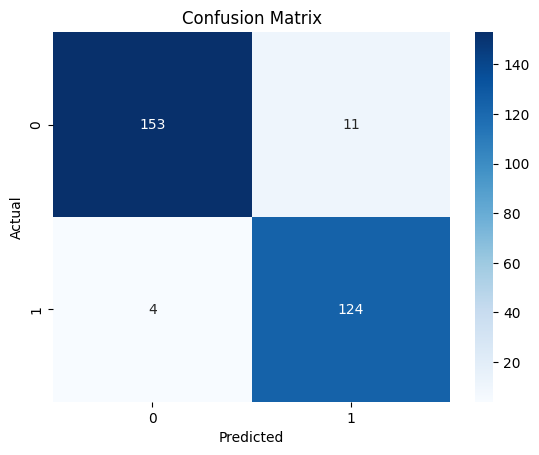

In [37]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_class, y_class_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [38]:

from sklearn.metrics import precision_score, recall_score

precision = precision_score(y_test_class, y_class_pred)
recall = recall_score(y_test_class, y_class_pred)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.9185185185185185
Recall: 0.96875


In [39]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


In [40]:

inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_train_processed)

    inertia_values.append(kmeans.inertia_)

print("Inertia Values:")
print(inertia_values)

Inertia Values:
[53114.54534368637, 50739.48282885599, 48644.93694631955, 47421.31687750932, 45946.72721816087, 44820.601764602914, 43723.12045346076, 42798.86049965477, 42195.81201438888]


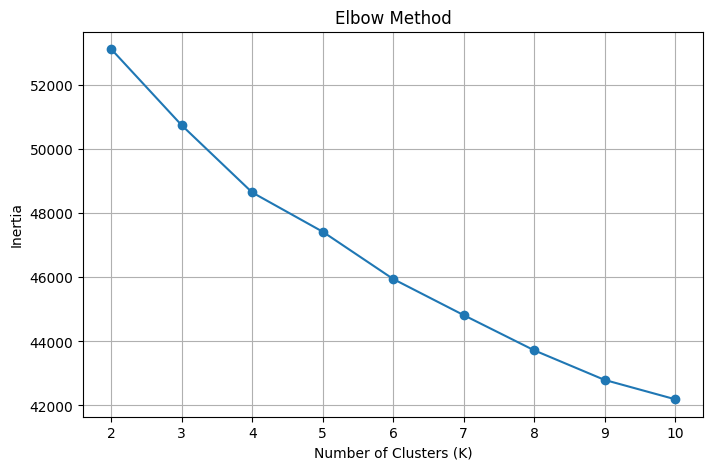

In [41]:

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia_values, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [42]:

# Train K-Means with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_train_processed)

# Calculate Silhouette Score
sil_score = silhouette_score(
    X_train_processed,
    cluster_labels
)

print("Silhouette Score:", sil_score)


Silhouette Score: 0.10437326438849838


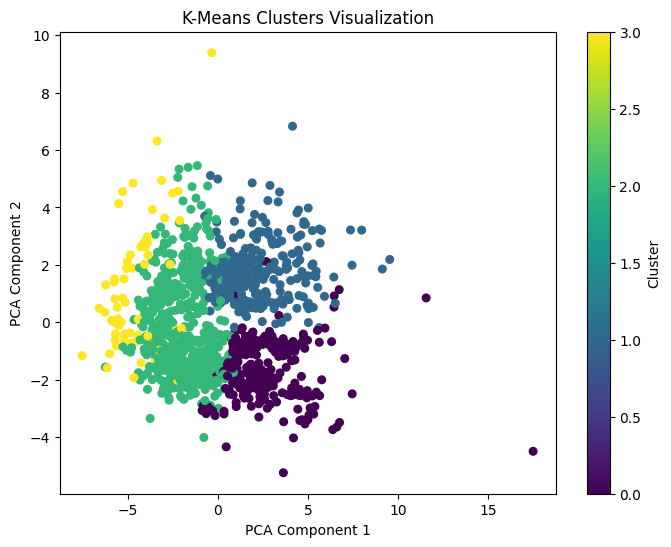

In [43]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Convert processed data to dense format if needed
X_dense = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

# Reduce data to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_dense)

# Plot clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=30
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("K-Means Clusters Visualization")
plt.colorbar(label="Cluster")
plt.show()


In [44]:

plt.savefig("kmeans_clusters.png", dpi=300, bbox_inches="tight")



<Figure size 640x480 with 0 Axes>

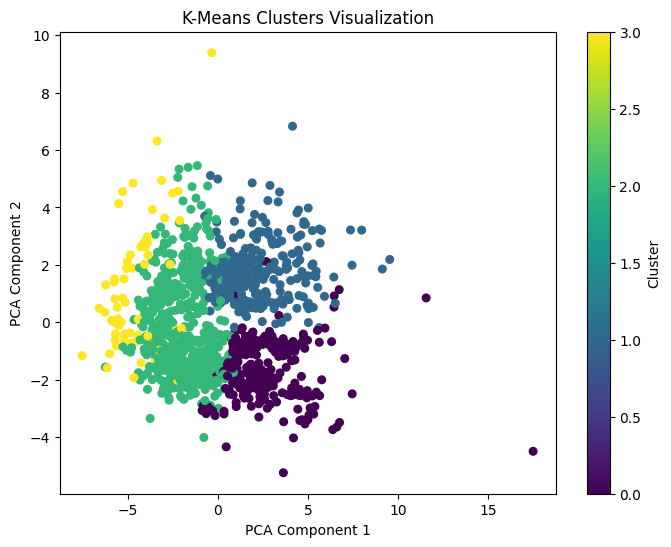

In [46]:

plt.figure(figsize=(8, 6))

# Draw the clusters
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=30
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("K-Means Clusters Visualization")

# Add colorbar
plt.colorbar(scatter, label="Cluster")

# Save the figure
plt.savefig(
    "/content/kmeans_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [47]:

import os

print(os.path.exists("/content/kmeans_clusters.png"))


True


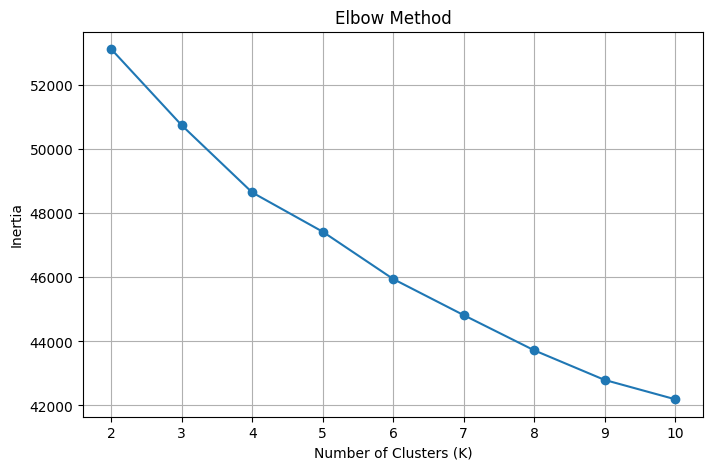

In [48]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)

# Save the figure
plt.savefig(
    "/content/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [49]:

import os

print("Clusters Image:",
      os.path.exists("/content/kmeans_clusters.png"))

print("Elbow Image:",
      os.path.exists("/content/elbow_method.png"))


Clusters Image: True
Elbow Image: True


In [50]:

import pandas as pd
import os

# Create results folder
os.makedirs("/content/results", exist_ok=True)

# Store model results
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression",
        "K-Means"
    ],
    "Metric": [
        "R2 Score",
        "Accuracy",
        "Silhouette Score"
    ],
    "Value": [
        0.4436545871,
        0.9486301370,
        0.1043732644
    ]
})

# Save results
results.to_csv(
    "/content/results/model_results.csv",
    index=False
)

print(results)
print("\nResults saved successfully!")


                 Model            Metric     Value
0    Linear Regression          R2 Score  0.443655
1  Logistic Regression          Accuracy  0.948630
2              K-Means  Silhouette Score  0.104373

Results saved successfully!


In [51]:

cm_df = pd.DataFrame(
    cm,
    index=["Actual Low Price", "Actual High Price"],
    columns=["Predicted Low Price", "Predicted High Price"]
)

cm_df.to_csv(
    "/content/results/confusion_matrix.csv"
)

print("Confusion Matrix saved successfully!")

Confusion Matrix saved successfully!


In [52]:
import os

files = [
    "/content/kmeans_clusters.png",
    "/content/elbow_method.png",
    "/content/results/model_results.csv",
    "/content/results/confusion_matrix.csv"
]

for file in files:
    print(file, "->", os.path.exists(file))



/content/kmeans_clusters.png -> True
/content/elbow_method.png -> True
/content/results/model_results.csv -> True
/content/results/confusion_matrix.csv -> True
